# 02. Tạo đặc trưng (T08): chọn đặc trưng bằng dữ liệu train

**Mục tiêu:** quyết định nên thêm đặc trưng mới nào vào `src/features.py::add_features`, và có bằng chứng cho Mục 2.4 của báo cáo.

Ứng viên lấy từ EDA (Mục 11 của `01_eda.ipynb`) và từ quyết định M1 (`docs/decisions.md`, Mục 3.3):

| Ứng viên | Cách tính | Câu hỏi cần trả lời |
|---|---|---|
| `arrival_weekday` | Thứ trong tuần của ngày đến | Tỉ lệ hủy có khác theo thứ không? Mô hình đã tự suy ra được chưa? |
| `has_history`, `prev_cancel_ratio` | Có lịch sử đặt phòng không; tỉ lệ booking trước đó bị hủy | Có giúp mô hình không, hay chỉ khuếch đại một hiện tượng riêng của năm 2015? |
| `has_agent`, `has_company` | `agent`/`company` khác `"none"` | Có thêm thông tin so với one-hot đã có không? |

**Nguyên tắc:**

- Chỉ dùng **tập train** (ngày đến 07/2015–12/2016). Chọn đặc trưng cũng là một quyết định mô hình hóa, nên không được nhìn validation hay test.
- So sánh bằng `time_series_cv` (5 fold theo thời gian, PR-AUC) trên train, giống cách nhóm chọn siêu tham số (`docs/decisions.md`, Mục 5.2).
- Kết quả ở đây là bước chọn đặc trưng, **không** ghi vào `reports/results/results.csv`.

**Kết quả (Mục 5):** chỉ thêm `arrival_weekday`.

## 0. Chuẩn bị

In [1]:
import sys
from pathlib import Path

# Make `src` importable whether the notebook runs from the project root or from notebooks/
ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.model_selection import TimeSeriesSplit

from src.config import CLEAN_CATEGORICAL_FEATURES, RANDOM_STATE, TARGET_COLUMN
from src.data import load_raw
from src.eda import cancel_rate_table, plot_cancel_rate, save_figure
from src.evaluate import time_series_cv
from src.preprocess import build_model_pipeline, build_preprocessor, clean_data
from src.split import temporal_split

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:.3f}".format)

TARGET = TARGET_COLUMN

# Pipeline order agreed at M1: load_raw -> clean_data -> (features) -> split
df = clean_data(load_raw())
train, _, _ = temporal_split(
    df, train_end="2017-01-01", valid_end="2017-07-01", date_col="arrival_date"
)
# Only the training period is used in this notebook.
del df

print(f"Train: {len(train):,} rows, arrival {train['arrival_date'].min():%d/%m/%Y} - "
      f"{train['arrival_date'].max():%d/%m/%Y}, cancellation rate {train[TARGET].mean():.1%}")

Train: 78,586 rows, arrival 01/07/2015 - 31/12/2016, cancellation rate 36.2%


Bộ cột sạch 22 cột lấy đúng theo `docs/decisions.md` (Mục 3.1). `src/config.py` hiện chỉ có danh sách biến phân loại, nên phần biến số được khai báo ở đây.

In [2]:
CLEAN_CATEGORICAL = list(CLEAN_CATEGORICAL_FEATURES)
CLEAN_NUMERIC = [
    "lead_time", "arrival_date_week_number", "arrival_date_day_of_month",
    "stays_in_weekend_nights", "stays_in_week_nights", "adults", "children", "babies",
    "is_repeated_guest", "previous_cancellations", "previous_bookings_not_canceled",
    "adr", "total_of_special_requests",
]
CLEAN_FEATURES = CLEAN_NUMERIC + CLEAN_CATEGORICAL
assert len(CLEAN_FEATURES) == 22 and len(set(CLEAN_FEATURES)) == 22

WEEKDAY_ORDER = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]


def candidate_features(data: pd.DataFrame) -> pd.DataFrame:
    # Row-wise candidates only; nothing is learned from the data.
    out = pd.DataFrame(index=data.index)
    out["arrival_weekday"] = data["arrival_date"].dt.day_name()
    total_prev = data["previous_cancellations"] + data["previous_bookings_not_canceled"]
    out["has_history"] = (total_prev > 0).astype(int)
    out["prev_cancel_ratio"] = (data["previous_cancellations"] / total_prev.where(total_prev > 0)).fillna(0.0)
    return out


train = train.join(candidate_features(train))
train[["arrival_weekday", "has_history", "prev_cancel_ratio"]].describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
arrival_weekday,78586,7,Friday,13562,NaN,NaN,NaN,NaN,NaN,NaN,NaN
has_history,78586.000,NaN,NaN,NaN,0.102,0.303,0.000,0.000,0.000,0.000,1.000
prev_cancel_ratio,78586.000,NaN,NaN,NaN,0.075,0.263,0.000,0.000,0.000,0.000,1.000


## 1. Tỉ lệ hủy theo từng ứng viên

**Mục đích:** xem ứng viên có tách được booking hủy và không hủy không. Đây mới là điều kiện cần; đặc trưng có tín hiệu vẫn có thể không giúp mô hình nếu thông tin đó đã nằm trong các cột khác (Mục 4 sẽ kiểm tra).

,n_bookings,share,cancel_rate
arrival_weekday,,,
Monday,11886,0.151,0.332
Tuesday,9108,0.116,0.320
Wednesday,10559,0.134,0.340
Thursday,12767,0.162,0.413
Friday,13562,0.173,0.403
Saturday,11884,0.151,0.381
Sunday,8820,0.112,0.311


,n_bookings,share,cancel_rate
has_history,,,
0,70571,0.898,0.319
1,8015,0.102,0.741


,n_bookings,share,cancel_rate
ratio_bucket,,,
no history,70571,0.898,0.319
1,5829,0.074,0.996
0,1813,0.023,0.025
"(0; 0,5]",333,0.004,0.198
"(0,5; 1)",40,0.001,0.475


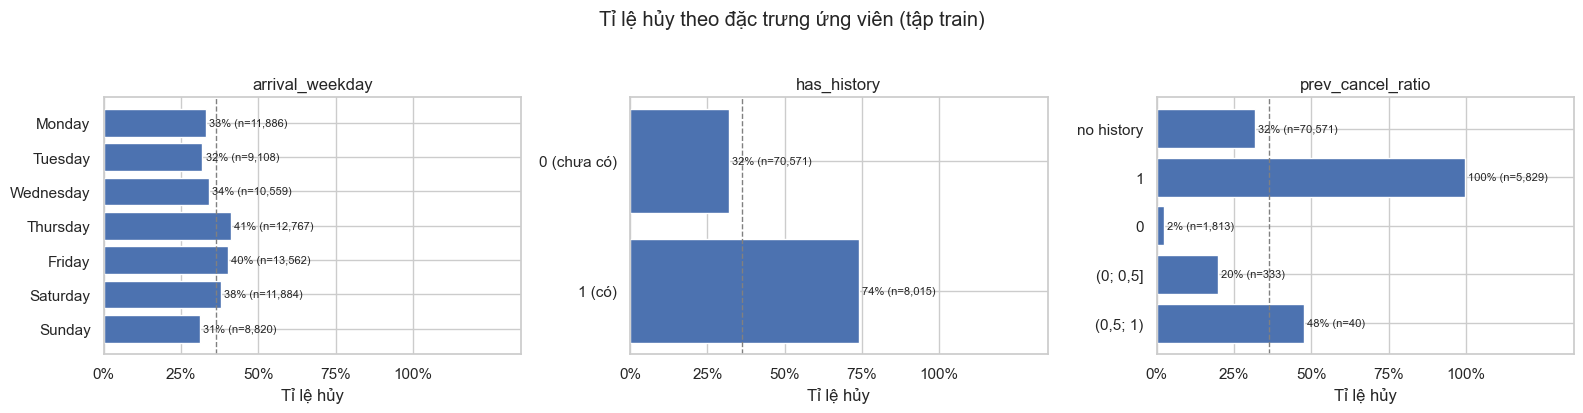

In [3]:
pos_rate = train[TARGET].mean()

weekday_table = cancel_rate_table(train, "arrival_weekday").reindex(WEEKDAY_ORDER)
history_table = cancel_rate_table(train, "has_history").sort_index()

ratio_bucket = pd.cut(
    train["prev_cancel_ratio"].where(train["has_history"] == 1),
    bins=[-0.01, 0, 0.5, 0.99, 1.0],
    labels=["0", "(0; 0,5]", "(0,5; 1)", "1"],
)
ratio_table = cancel_rate_table(
    train.assign(ratio_bucket=ratio_bucket.astype("string").fillna("no history")), "ratio_bucket"
)

display(weekday_table)
display(history_table)
display(ratio_table)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
plot_cancel_rate(weekday_table, axes[0], overall=pos_rate, title="arrival_weekday")
plot_cancel_rate(history_table.rename(index={0: "0 (chưa có)", 1: "1 (có)"}), axes[1],
                 overall=pos_rate, title="has_history")
plot_cancel_rate(ratio_table, axes[2], overall=pos_rate, title="prev_cancel_ratio")
fig.suptitle("Tỉ lệ hủy theo đặc trưng ứng viên (tập train)", y=1.03)
fig.tight_layout()
save_figure(fig, "feature_candidates")
plt.show()

**Nhận xét:**

- **`arrival_weekday`:** tỉ lệ hủy thấp nhất ở Chủ nhật (31,1%) và thứ Ba (32,0%), cao nhất ở thứ Sáu (40,3%) và thứ Năm (41,3%). Chênh lệch khoảng 10 điểm %, và mỗi thứ có từ 8.820 đến 13.562 booking, nên không phải do nhóm quá nhỏ.
  - Thứ trong tuần của ngày đến đã biết ngay lúc đặt phòng, nên không gây rò rỉ.
  - Bộ cột sạch đã bỏ `arrival_date_year`. Không có năm thì mô hình không tự tính được thứ từ tuần và ngày trong tháng, nên đây là thông tin mới với mô hình.
- **`has_history`:** có lịch sử đặt phòng thì hủy 74,1%, so với 31,9%. Nhưng cờ này gộp hai nhóm ngược nhau:
  - lịch sử toàn hủy (`prev_cancel_ratio` = 1): hủy 99,6%, 5.829 dòng;
  - lịch sử không hủy lần nào (`prev_cancel_ratio` = 0): chỉ hủy 2,5%, 1.813 dòng.

  Bản thân cờ không mang ý nghĩa rõ ràng; tín hiệu nằm ở `prev_cancel_ratio`.
- **`prev_cancel_ratio` = 1** hủy 99,6% trên 5.829 dòng (7,4% train). Tỉ lệ gần 100% trên hàng nghìn dòng là kiểu bất thường đã gặp ở `deposit_type`, nên Mục 3 xem kỹ nhóm này.

## 2. `has_agent`, `has_company` có thêm thông tin không?

**Mục đích:** EDA đề xuất hai cờ này (không qua đại lý hủy 24,7% so với 39,0%; có công ty hủy 17,5% so với 38,2%). Nhưng M1 đã chốt mã hóa `agent` và `company` bằng one-hot có mức `"none"`, và `build_preprocessor` của T07 gom các mã chiếm dưới 1% train vào một cột chung. Ô dưới fit bộ mã hóa đó trên train rồi so cột one-hot với hai cờ.

In [4]:
id_cols = ["agent", "company"]
encoder = build_preprocessor(
    train[id_cols], numeric_features=[], categorical_features=id_cols
).fit(train[id_cols])
encoded = encoder.transform(train[id_cols])
encoded = encoded.toarray() if hasattr(encoded, "toarray") else encoded
encoded = pd.DataFrame(encoded, columns=encoder.get_feature_names_out(), index=train.index)

company_cols = [c for c in encoded.columns if "company" in c]
agent_cols = [c for c in encoded.columns if "agent" in c]
print(f"company -> {len(company_cols)} one-hot columns: {company_cols}")
print(f"agent   -> {len(agent_cols)} one-hot columns (incl. 'none' and infrequent)")

has_agent = (train["agent"] != "none").astype(int)
has_company = (train["company"] != "none").astype(int)
print("has_agent   == 1 - agent_none   :", (has_agent == 1 - encoded["categorical__agent_none"]).all())
print("has_company == 1 - company_none :", (has_company == 1 - encoded["categorical__company_none"]).all())

company -> 2 one-hot columns: ['categorical__company_none', 'categorical__company_infrequent_sklearn']
agent   -> 14 one-hot columns (incl. 'none' and infrequent)
has_agent   == 1 - agent_none   : True
has_company == 1 - company_none : True


**Nhận xét:**

- Với `min_frequency=0.01`, mọi mã công ty đều chiếm dưới 1% train. Vì vậy `company` chỉ còn 2 cột: `none` và nhóm mã hiếm. Nói cách khác, one-hot của `company` **chính là** `has_company`.
- `agent` còn 14 cột, trong đó có cột riêng cho `none`.
- Kiểm tra trên toàn bộ train cho thấy `has_agent` = 1 − `agent_none` và `has_company` = 1 − `company_none` ở mọi dòng.
- **Kết luận: không thêm `has_agent`, `has_company`**, vì hai cờ này trùng hoàn toàn với cột one-hot đã có. Tín hiệu mà EDA ghi nhận vẫn được mô hình dùng, thông qua cột `none`.

## 3. `previous_cancellations`: tín hiệu thật hay hiện tượng riêng của năm 2015?

**Mục đích:** ở Mục 1, nhóm booking có toàn bộ lịch sử là hủy (`prev_cancel_ratio` = 1) có tỉ lệ hủy gần 100%. EDA (Mục 6) đã thấy `previous_cancellations` = 1 hủy 94% và phần lớn là dòng trùng của các khối booking đoàn. Ô dưới xem nhóm này là ai và rơi vào giai đoạn nào.

In [5]:
prev_all_canceled = (train["previous_cancellations"] > 0) & (train["previous_bookings_not_canceled"] == 0)
grp = train[prev_all_canceled]
original_cols = [c for c in train.columns if c not in ["arrival_date", "arrival_weekday", "has_history", "prev_cancel_ratio"]]
has_copy = train[original_cols].duplicated(keep=False)

print(f"Rows with only canceled history: {len(grp):,} ({len(grp) / len(train):.1%} of train), "
      f"cancellation rate {grp[TARGET].mean():.1%}")
print(f"  share with an identical copy in train: {has_copy[grp.index].mean():.1%} "
      f"(whole train: {has_copy.mean():.1%})")
print(f"  market_segment: {grp['market_segment'].value_counts(normalize=True).head(3).round(3).to_dict()}")
print(f"  hotel: {grp['hotel'].value_counts(normalize=True).round(3).to_dict()}")
print(f"  previous_cancellations == 1: {(grp['previous_cancellations'] == 1).mean():.1%}")

by_quarter = (
    train.assign(quarter=train["arrival_date"].dt.to_period("Q").astype(str), flag=prev_all_canceled)
    .groupby("quarter")
    .agg(n_bookings=(TARGET, "size"), n_flagged=("flag", "sum"))
)
by_quarter["flagged_share"] = by_quarter["n_flagged"] / by_quarter["n_bookings"]
by_quarter["flagged_cancel_rate"] = grp.groupby(grp["arrival_date"].dt.to_period("Q").astype(str))[TARGET].mean()
by_quarter

Rows with only canceled history: 5,829 (7.4% of train), cancellation rate 99.6%
  share with an identical copy in train: 88.9% (whole train: 36.2%)
  market_segment: {'Groups': 0.571, 'Offline TA/TO': 0.284, 'Online TA': 0.099}
  hotel: {'City Hotel': 0.849, 'Resort Hotel': 0.151}
  previous_cancellations == 1: 97.0%


,n_bookings,n_flagged,flagged_share,flagged_cancel_rate
quarter,,,,
2015Q3,11765,2792,0.237,1.000
2015Q4,10200,1592,0.156,0.997
2016Q1,10949,815,0.074,0.988
2016Q2,16190,383,0.024,0.995
2016Q3,15006,137,0.009,0.993
2016Q4,14476,110,0.008,0.955


**Nhận xét:**

- **Nhóm này là các khối booking đoàn, không giống hành vi của một khách cá nhân.** Trong 5.829 booking có lịch sử toàn hủy:
  - 88,9% có một dòng giống hệt trong train (cả train chỉ 36,2%);
  - 57,1% thuộc Groups, 84,9% ở City Hotel;
  - 97,0% có đúng 1 lần hủy trước đó.

  Đây chính là các khối booking đoàn mà EDA đã gặp (`01_eda.ipynb`, Mục 4 và 6).
- **Hiện tượng giảm dần theo thời gian.** Nhóm này chiếm 23,7% booking của quý 3/2015 và 15,6% của quý 4/2015, nhưng chỉ còn 0,8–0,9% ở nửa sau 2016. Tập test (07–08/2017) gần như không có nhóm này.
- **Vì sao vẫn giữ cột gốc nhưng không tạo đặc trưng mới.**
  - Theo bài báo, `previous_cancellations` đếm các lần hủy *trước* booking hiện tại. Không có bằng chứng về cơ chế rò rỉ, nên M1 giữ cột này trong bộ sạch.
  - Ngược lại, `prev_cancel_ratio` tách đúng nhóm này ra (ratio = 1). Đặc trưng đó sẽ giúp mô hình học thuộc một hiện tượng của năm 2015 mà không còn xuất hiện ở năm 2017.
- **Hệ quả cho TN1 và Mục 5.3.** Chia ngẫu nhiên đưa các khối này vào cả train lẫn test nên được lợi, còn chia theo thời gian thì không. Cần ghi điều này vào phần hạn chế.

## 4. Ứng viên có giúp mô hình không? So sánh bằng CV theo thời gian

**Mục đích:** một đặc trưng có tín hiệu (Mục 1) chỉ đáng thêm nếu mô hình chưa tự lấy được thông tin đó từ các cột sẵn có. Cách kiểm tra: huấn luyện cùng một mô hình với bộ cột sạch, rồi với bộ cột sạch cộng thêm ứng viên, và so PR-AUC trên từng fold.

- **Dữ liệu:** train đã sắp xếp theo ngày đến (`temporal_split` trả về sẵn), chia 5 fold bằng `time_series_cv`: mỗi fold học phần trước, đánh giá trên phần sau.
- **Mô hình:** Logistic Regression (tuyến tính, không tự tạo tương tác giữa các cột) và Random Forest (tự tìm tương tác). Hai mô hình dùng tham số mặc định, chưa tune; mục đích là so các bộ cột với nhau, không phải tìm mô hình tốt nhất.
- **Quy tắc giữ (đặt trước khi chạy):** giữ đặc trưng nếu PR-AUC tăng ở ít nhất 4/5 fold với ít nhất một mô hình và có lý do nghiệp vụ. Riêng `prev_cancel_ratio`/`has_history` còn phải tăng ở 2 fold cuối (nửa sau 2016), giai đoạn hiện tượng ở Mục 3 đã gần hết.

In [6]:
# Date range of each validation fold (same splitter as time_series_cv)
fold_ranges = pd.DataFrame(
    [
        {
            "fold": i,
            "train_rows": len(tr),
            "valid_from": train["arrival_date"].iloc[va].min().strftime("%d/%m/%Y"),
            "valid_to": train["arrival_date"].iloc[va].max().strftime("%d/%m/%Y"),
            "valid_cancel_rate": train[TARGET].iloc[va].mean(),
        }
        for i, (tr, va) in enumerate(TimeSeriesSplit(n_splits=5).split(train), start=1)
    ]
).set_index("fold")
fold_ranges

,train_rows,valid_from,valid_to,valid_cancel_rate
fold,,,,
1,13101,08/10/2015,17/02/2016,0.288
2,26198,17/02/2016,06/05/2016,0.355
3,39295,06/05/2016,23/07/2016,0.367
4,52392,23/07/2016,08/10/2016,0.367
5,65489,08/10/2016,31/12/2016,0.378


In [7]:
FEATURE_SETS = {
    "clean (22)": ([], []),
    "+ arrival_weekday": ([], ["arrival_weekday"]),
    "+ prev_cancel_ratio, has_history": (["prev_cancel_ratio", "has_history"], []),
}
MODELS = {
    "Logistic Regression": (LogisticRegression(max_iter=2000, random_state=RANDOM_STATE), True),
    "Random Forest": (RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=RANDOM_STATE), False),
}

cv_rows = []
for model_name, (estimator, scale_numeric) in MODELS.items():
    for set_name, (extra_numeric, extra_categorical) in FEATURE_SETS.items():
        numeric = CLEAN_NUMERIC + extra_numeric
        categorical = CLEAN_CATEGORICAL + extra_categorical
        X = train[numeric + categorical]
        pipeline = build_model_pipeline(
            X, estimator,
            numeric_features=numeric, categorical_features=categorical,
            scale_numeric=scale_numeric,
        )
        scores = time_series_cv(pipeline, X, train[TARGET], n_splits=5, scoring="average_precision")
        cv_rows.append(scores.assign(model=model_name, features=set_name))

cv_all = pd.concat(cv_rows, ignore_index=True)

summary = (
    cv_all.groupby(["model", "features"], sort=False)["score"]
    .agg(pr_auc_mean="mean", pr_auc_std="std")
)
summary

pr_auc_mean  pr_auc_std
model               features                                                 
Logistic Regression clean (22)                              0.700       0.124
                    + arrival_weekday                       0.752       0.012
                    + prev_cancel_ratio, has_history        0.730       0.060
Random Forest       clean (22)                              0.765       0.018
                    + arrival_weekday                       0.770       0.018
                    + prev_cancel_ratio, has_history        0.761       0.024

In [8]:
per_fold = cv_all.pivot_table(index=["model", "fold"], columns="features", values="score")[list(FEATURE_SETS)]
delta = per_fold.drop(columns="clean (22)").sub(per_fold["clean (22)"], axis=0)

print("PR-AUC difference vs the clean set, per fold (positive = candidate helps):")
display(delta.style.format("{:+.4f}"))

improved = (delta > 0).groupby("model").sum()
last_two = delta[delta.index.get_level_values("fold") >= 4].groupby("model").apply(lambda d: (d > 0).all())
print("Folds improved (out of 5):")
display(improved)
print("Improved in both of the last two folds:")
display(last_two)

PR-AUC difference vs the clean set, per fold (positive = candidate helps):


Folds improved (out of 5):


features,+ arrival_weekday,"+ prev_cancel_ratio, has_history"
model,,
Logistic Regression,3,3
Random Forest,4,2


Improved in both of the last two folds:


features,+ arrival_weekday,"+ prev_cancel_ratio, has_history"
model,,
Logistic Regression,False,False
Random Forest,True,False


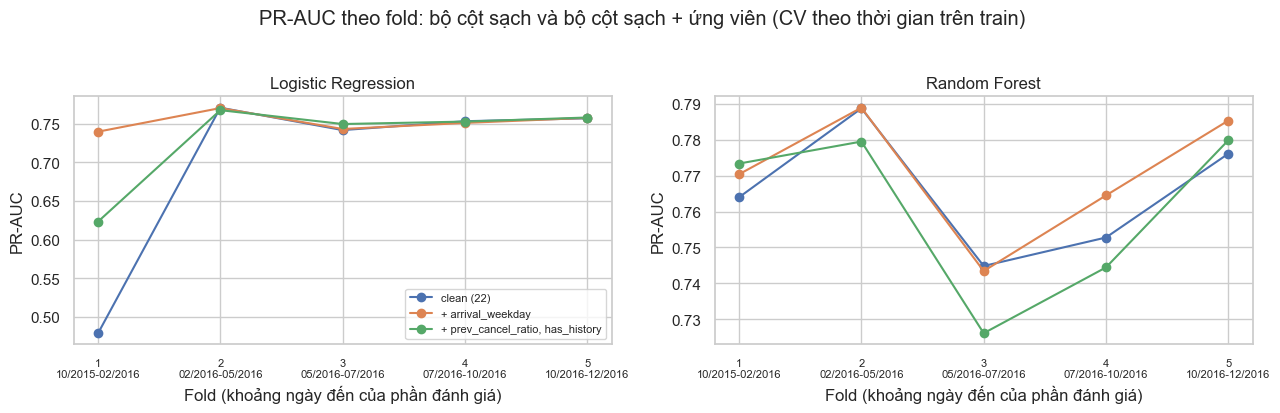

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=False)
for ax, model_name in zip(axes, MODELS):
    data = per_fold.loc[model_name]
    for set_name in FEATURE_SETS:
        ax.plot(data.index, data[set_name], marker="o", label=set_name)
    ax.set_xticks(fold_ranges.index,
                  [f"{i}\n{r.valid_from[3:]}-{r.valid_to[3:]}" for i, r in fold_ranges.iterrows()],
                  fontsize=8)
    ax.set_xlabel("Fold (khoảng ngày đến của phần đánh giá)")
    ax.set_ylabel("PR-AUC")
    ax.set_title(model_name)
axes[0].legend(fontsize=8)
fig.suptitle("PR-AUC theo fold: bộ cột sạch và bộ cột sạch + ứng viên (CV theo thời gian trên train)", y=1.03)
fig.tight_layout()
save_figure(fig, "feature_ablation_cv")
plt.show()

### 4.1. Vì sao Logistic Regression ở fold 1 lệch mạnh?

Ở bộ cột sạch, Logistic Regression có PR-AUC 0,700 ± 0,124, độ lệch chuẩn gấp khoảng 10 lần các cấu hình khác. Riêng fold 1, thêm `arrival_weekday` làm PR-AUC tăng tới +0,26, trong khi 4 fold còn lại chỉ thay đổi từ −0,002 đến +0,001. Ô dưới kiểm tra giả thuyết: lỗi đến từ `arrival_date_week_number`.

In [10]:
numeric_no_week = [c for c in CLEAN_NUMERIC if c != "arrival_date_week_number"]
rows = []
for fold, (tr, va) in enumerate(TimeSeriesSplit(n_splits=5).split(train), start=1):
    fit_part, eval_part = train.iloc[tr], train.iloc[va]
    row = {
        "fold": fold,
        "train_weeks": f"{fit_part['arrival_date_week_number'].min()}-{fit_part['arrival_date_week_number'].max()}",
    }
    for label, numeric in [("clean", CLEAN_NUMERIC), ("clean without week_number", numeric_no_week)]:
        X_fit = fit_part[numeric + CLEAN_CATEGORICAL]
        pipeline = build_model_pipeline(
            X_fit, LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
            numeric_features=numeric, categorical_features=CLEAN_CATEGORICAL,
        ).fit(X_fit, fit_part[TARGET])
        scores = pipeline.predict_proba(eval_part[numeric + CLEAN_CATEGORICAL])[:, 1]
        row[label] = average_precision_score(eval_part[TARGET], scores)
    rows.append(row)
pd.DataFrame(rows).set_index("fold")

,train_weeks,clean,clean without week_number
fold,,,
1,27-41,0.479,0.729
2,1-53,0.771,0.773
3,1-53,0.742,0.742
4,1-53,0.753,0.753
5,1-53,0.757,0.757


**Nhận xét:**

- **Nguyên nhân là ngoại suy tuyến tính.** Fold 1 chỉ học trên các tuần 27–41 (07–10/2015) nhưng phải đánh giá cả các tuần 1–7 (01–02/2016). Logistic Regression coi `arrival_date_week_number` là một con số và học một hệ số tuyến tính trên khoảng tuần hẹp, rồi kéo dài hệ số đó sang các tuần chưa từng thấy, nên xếp hạng sai. Bỏ cột này thì PR-AUC fold 1 tăng từ 0,479 lên 0,729, còn các fold khác gần như giữ nguyên.
- **Mức tăng +0,26 của `arrival_weekday` ở fold 1 không phải tác dụng thật.** Thêm cột này chỉ tình cờ làm hệ số của `arrival_date_week_number` gần bằng 0. Vì vậy khi xét `arrival_weekday`, không tính fold 1 của Logistic Regression.
- **Mô hình cuối không bị ảnh hưởng**, vì train đầy đủ (2015–2016) có đủ các tuần 1–53. Nhưng con số mean ± std của CV cho Logistic Regression thì bị ảnh hưởng. Ghi chú cho TV1 (T10): cân nhắc bỏ `arrival_date_week_number` khỏi Logistic Regression (mùa vụ đã có trong `arrival_date_month`), hoặc giải thích fold 1 khi báo cáo CV.

**Nhận xét về kết quả so sánh (Mục 4):**

- **`arrival_weekday`:**
  - Random Forest tăng PR-AUC ở 4/5 fold (+0,006; +0,000; −0,001; +0,012; +0,009), trung bình từ 0,765 lên 0,770. Mức tăng nhỏ, nhưng có mặt ở cả 2 fold cuối, là các fold mô hình học trên nhiều dữ liệu nhất.
  - Logistic Regression, khi bỏ fold 1 (Mục 4.1), chỉ thay đổi từ −0,002 đến +0,001, tức gần như không đổi.
- **`prev_cancel_ratio`, `has_history`:**
  - Random Forest giảm ở fold 2–4 (−0,009; −0,019; −0,008) và chỉ tăng ở 2/5 fold.
  - Logistic Regression, ngoài fold 1, thay đổi dưới 0,01.

  Không đạt quy tắc, kể cả điều kiện tăng ở 2 fold cuối. Điều này khớp với Mục 3: tín hiệu chủ yếu đến từ các khối đoàn năm 2015.
- **Kết luận theo quy tắc đã đặt trước:**
  - **Giữ `arrival_weekday`**: Random Forest tăng ở 4/5 fold, và có lý do nghiệp vụ.
  - **Không thêm** `prev_cancel_ratio`, `has_history` (Mục 3, 4) và `has_agent`, `has_company` (Mục 2).
- **Trình bày đúng mức trong báo cáo:** `arrival_weekday` chỉ cải thiện khoảng 0,005 PR-AUC. Đặc trưng này bổ sung thông tin về chu kỳ trong tuần mà bộ cột sạch không có, không phải một cải thiện lớn.

## 5. Kết luận và kiểm tra `add_features`

| Ứng viên | Bằng chứng | Quyết định |
|---|---|---|
| `arrival_weekday` | Tỉ lệ hủy 31,1% (Chủ nhật) đến 41,3% (thứ Năm); Random Forest tăng PR-AUC ở 4/5 fold; bộ cột sạch không tự suy ra được | **Thêm** (cả bộ sạch và bộ thông thường) |
| `prev_cancel_ratio`, `has_history` | Tín hiệu đến từ các khối booking đoàn năm 2015; Random Forest giảm ở fold 2–4 | Không thêm |
| `has_agent`, `has_company` | Trùng hoàn toàn với cột one-hot `none` | Không thêm |
| `country_group` | Chỉ dùng cho bộ thông thường; one-hot `country` đã giữ PRT và các nước lớn | Không thêm |
| `total_nights`, `total_guests`, `booking_*`, `has_children` | EDA Mục 11 đã loại vì không có bằng chứng | Không thêm |

`src/features.py::add_features` chỉ tạo `arrival_weekday`. Hai hằng số `ENGINEERED_CATEGORICAL_FEATURES` và `ENGINEERED_NUMERIC_FEATURES` cho biết cần nối thêm cột nào vào danh sách đặc trưng. Ô dưới gọi hàm trên dữ liệu train và đối chiếu với cột đã phân tích ở trên.

In [11]:
from src.features import ENGINEERED_CATEGORICAL_FEATURES, ENGINEERED_NUMERIC_FEATURES, add_features

base = train.drop(columns=["arrival_weekday", "has_history", "prev_cancel_ratio"])
featured = add_features(base)

assert featured.index.equals(base.index) and len(featured) == len(base)
assert "arrival_weekday" not in base.columns  # input left unchanged (copy=True)
assert featured["arrival_weekday"].equals(train["arrival_weekday"])

print("ENGINEERED_CATEGORICAL_FEATURES:", ENGINEERED_CATEGORICAL_FEATURES)
print("ENGINEERED_NUMERIC_FEATURES:    ", ENGINEERED_NUMERIC_FEATURES)
print(f"Clean set used by the models: {len(CLEAN_FEATURES)} columns + "
      f"{len(ENGINEERED_CATEGORICAL_FEATURES) + len(ENGINEERED_NUMERIC_FEATURES)} engineered")

ENGINEERED_CATEGORICAL_FEATURES: ['arrival_weekday']
ENGINEERED_NUMERIC_FEATURES:     []
Clean set used by the models: 22 columns + 1 engineered
